In [43]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns


In [65]:
df=pd.read_csv(r'C:\Users\World\Downloads\Compressed/clv_data.csv' ,)
df

,id,age,gender,income,days_on_platform,city,purchases
0,0,NaN,Male,126895,14.0,San Francisco,0
1,1,NaN,Male,161474,14.0,Tokyo,0
2,2,24.0,Male,104723,34.0,London,1
3,3,29.0,Male,43791,28.0,London,2
4,4,18.0,Female,132181,26.0,London,2
...,...,...,...,...,...,...,...
4995,4995,NaN,Female,212261,28.0,San Francisco,1
4996,4996,NaN,Male,70228,12.0,San Francisco,0
4997,4997,NaN,Male,64995,14.0,New York City,0
4998,4998,NaN,Male,56144,4.0,New York City,2


In [52]:
df.isna().sum()

id                     0
age                 2446
gender                 0
income                 0
days_on_platform     141
city                   0
purchases              0
dtype: int64

In [53]:
df['age'].fillna(df['age'].mean(),inplace=True)
df['days_on_platform'].fillna(df['days_on_platform'].mean(),inplace=True)
df
q25 = df.select_dtypes(include=['number']).apply(lambda x: np.percentile(x, 25))
print(q25)
q75 = df.select_dtypes(include=['number']).apply(lambda x: np.percentile(x, 75))
print(q75)
# df.describe()
iqr=q75-q25
lower=q25-1.5*iqr
upper=q75+1.5*iqr
lower,upper

id                   1249.75
age                    30.00
income              32752.50
days_on_platform       10.00
purchases               0.00
dtype: float64
id                    3749.25
age                     31.00
income              115406.50
days_on_platform        34.00
purchases                2.00
dtype: float64


C:\Users\World\AppData\Local\Temp\ipykernel_6732\4259665178.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].mean(),inplace=True)
C:\Users\World\AppData\Local\Temp\ipykernel_6732\4259665178.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For exampl

(id                  -2499.5
 age                    28.5
 income             -91228.5
 days_on_platform      -26.0
 purchases              -3.0
 dtype: float64,
 id                    7498.5
 age                     32.5
 income              239387.5
 days_on_platform        70.0
 purchases                5.0
 dtype: float64)

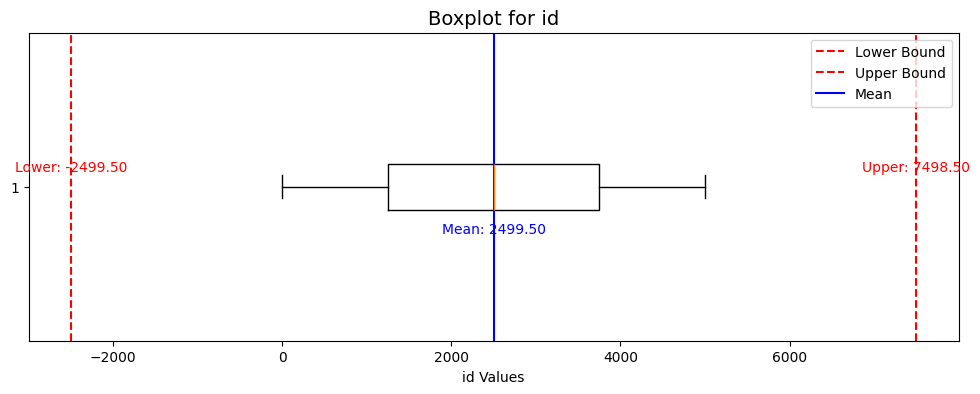

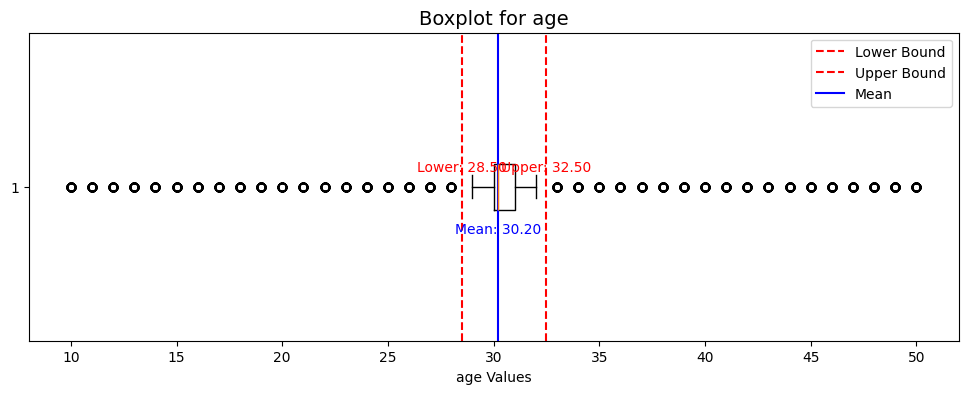

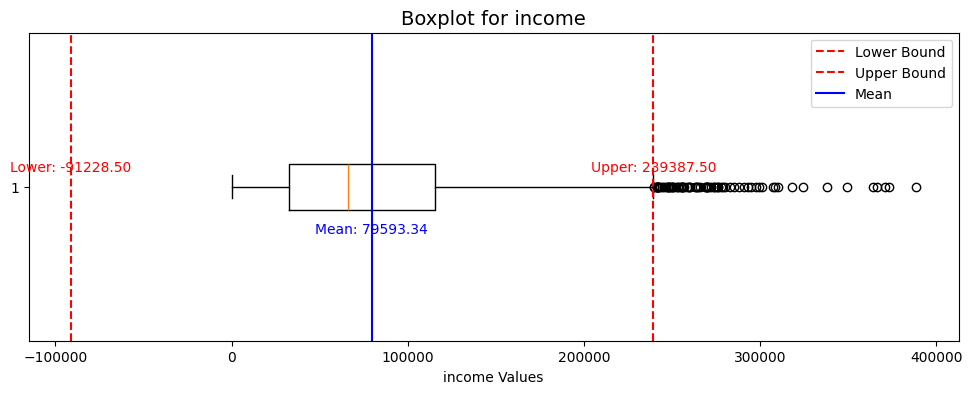

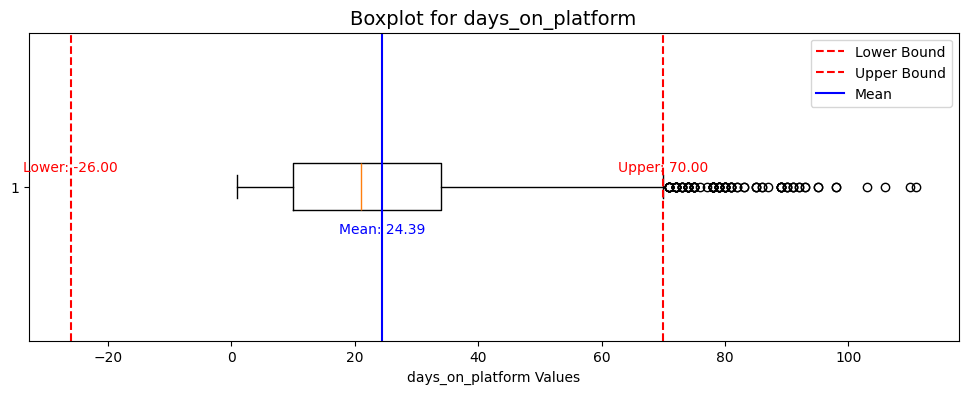

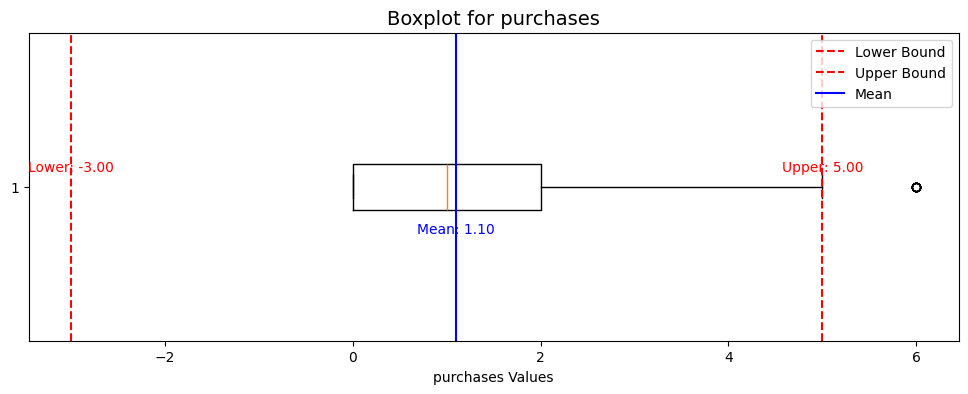

In [54]:
cols = df.columns

for col in cols:
    if np.issubdtype(df[col].dtype, np.number):  # Only numeric columns
        # Calculate statistics
        Q1 = np.percentile(df[col], 25)
        Q3 = np.percentile(df[col], 75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        mean_val = df[col].mean()

        # Create figure
        plt.figure(figsize=(12, 4))
        plt.title(f"Boxplot for {col}", fontsize=14)

        # Draw boxplot (horizontal)
        plt.boxplot(x=df[col], vert=False)

        # Draw lower & upper bound lines
        plt.axvline(lower, color='red', linestyle='--', label='Lower Bound')
        plt.axvline(upper, color='red', linestyle='--', label='Upper Bound')
        # plt.vlines(x=lower, ymin=0.85, ymax=1.15, color='red', linestyle='--', label='Lower Bound')

        # Draw mean line
        plt.axvline(mean_val, color='blue', linestyle='-', label='Mean')

        # Add text annotations
        plt.text(lower, 1.05, f"Lower: {lower:.2f}", color='red', fontsize=10, ha='center')
        plt.text(upper, 1.05, f"Upper: {upper:.2f}", color='red', fontsize=10, ha='center')
        plt.text(mean_val, 0.85, f"Mean: {mean_val:.2f}", color='blue', fontsize=10, ha='center')

        # Labels & legend
        plt.xlabel(f"{col} Values")
        plt.legend()
        plt.show()



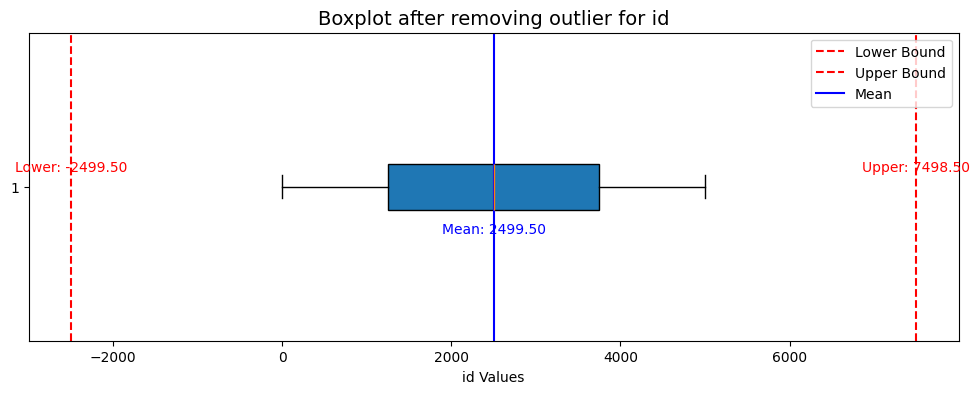

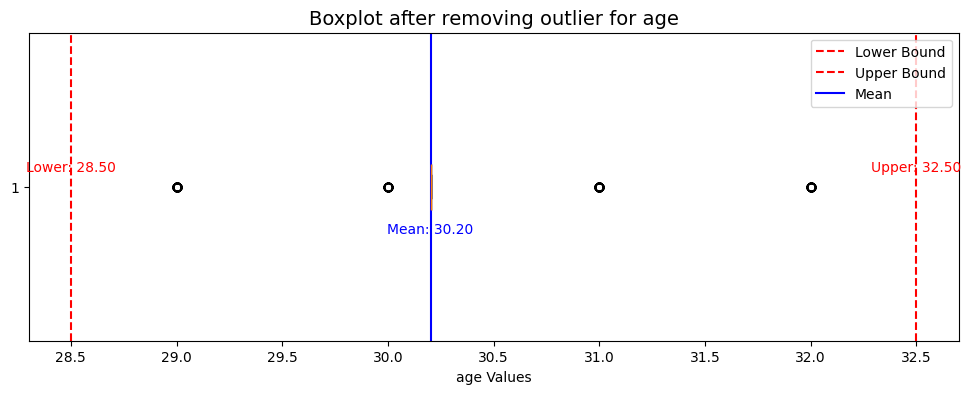

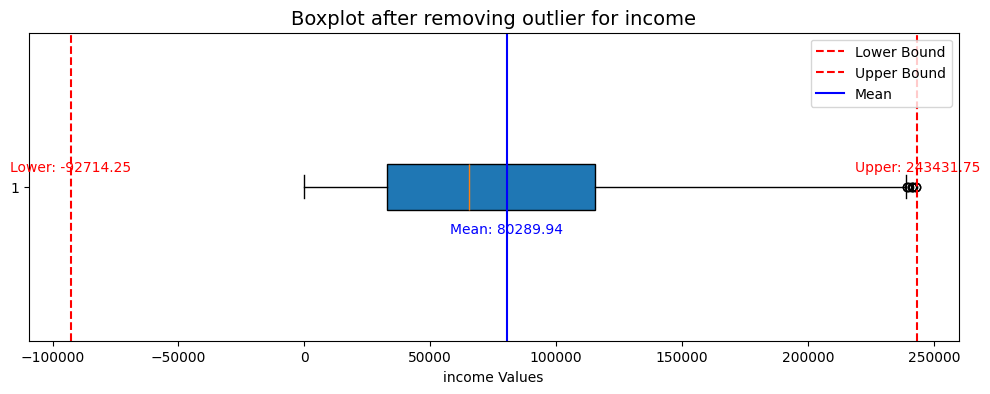

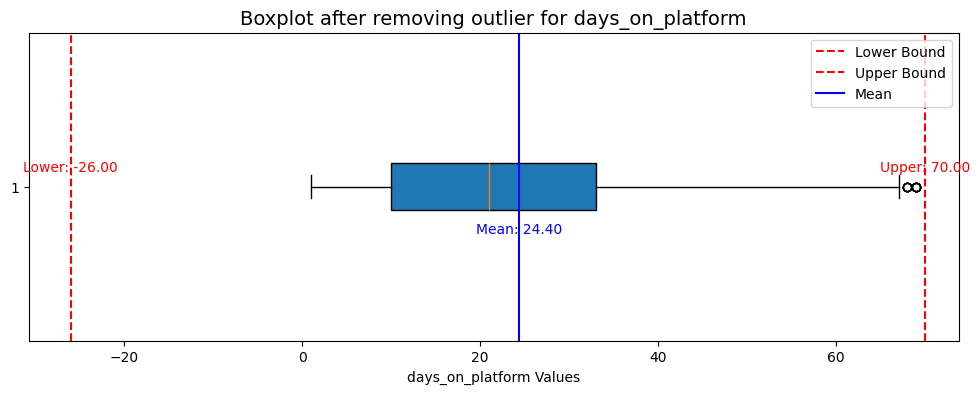

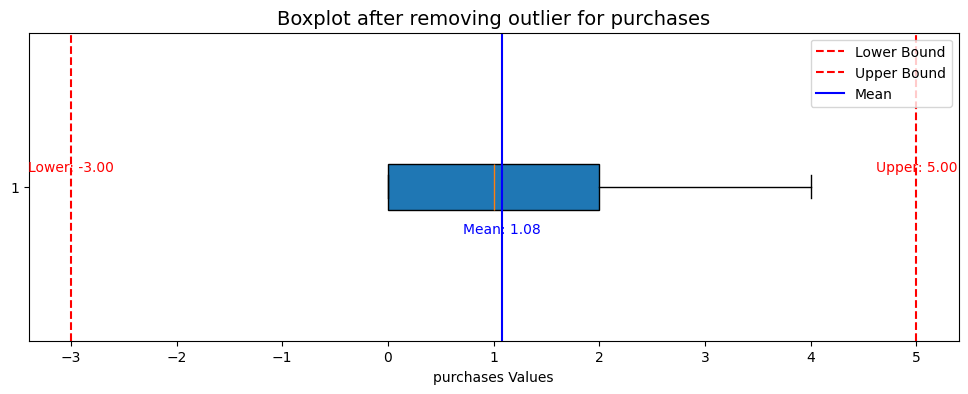

In [55]:
cols = df.columns
for col in cols:
    if np.issubdtype(df[col].dtype, np.number):  # Only numeric columns
        # Calculate statistics
        Q1 = np.percentile(df[col], 25)
        Q3 = np.percentile(df[col], 75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        mean_val = df[col].mean()

        # Filter data to remove outliers for plotting
        df = df[(df[col] > lower) & (df[col] < upper)]
        # Create figure
        plt.figure(figsize=(12, 4))
        plt.title(f"Boxplot after removing outlier for {col}", fontsize=14)

        # Draw boxplot (horizontal)
        plt.boxplot(x= df[col], vert=False, patch_artist=True)

        # Draw lower & upper bound lines
        plt.axvline(lower, color='red', linestyle='--', label='Lower Bound')
        plt.axvline(upper, color='red', linestyle='--', label='Upper Bound')

        # Draw mean line
        plt.axvline(mean_val, color='blue', linestyle='-', label='Mean')

        # Add text annotations
        plt.text(lower, 1.05, f"Lower: {lower:.2f}", color='red', fontsize=10, ha='center')
        plt.text(upper, 1.05, f"Upper: {upper:.2f}", color='red', fontsize=10, ha='center')
        plt.text(mean_val, 0.85, f"Mean: {mean_val:.2f}", color='blue', fontsize=10, ha='center')

        # Labels & legend
        plt.xlabel(f"{col} Values")
        plt.legend()
        plt.show()


In [56]:
df

,id,age,gender,income,days_on_platform,city,purchases
0,0,30.202036,Male,126895,14.0,San Francisco,0
1,1,30.202036,Male,161474,14.0,Tokyo,0
3,3,29.000000,Male,43791,28.0,London,2
6,6,30.202036,Male,51679,30.0,Tokyo,0
7,7,30.202036,Female,53341,43.0,San Francisco,1
...,...,...,...,...,...,...,...
4995,4995,30.202036,Female,212261,28.0,San Francisco,1
4996,4996,30.202036,Male,70228,12.0,San Francisco,0
4997,4997,30.202036,Male,64995,14.0,New York City,0
4998,4998,30.202036,Male,56144,4.0,New York City,2


In [66]:
# ---------- imports ----------
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, PowerTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# ---------- Quick diagnostics ----------
print("Dataset shape:", df.shape)
print("Missing per column:\n", df.isna().sum())
print("\nValue counts for 'purchases':\n", df['purchases'].value_counts())

# ---------- prepare X,y ----------
X = df.drop(columns=['id','purchases'])
y = df['purchases']

# detect columns automatically
numeric_cols = X.select_dtypes(include=['number']).columns.tolist()    # e.g. ['age','income','days_on_platform']
cat_cols = X.select_dtypes(include=['object','category']).columns.tolist()  # e.g. ['gender','city']
print("Numeric cols:", numeric_cols)
print("Categorical cols:", cat_cols)

# ---------- transformers ----------
# Numeric: median impute (robust), power transform to reduce skew, robust scaler to reduce outlier effect
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),            # median handles NaNs in 'age'
    ('power', PowerTransformer(method='yeo-johnson', standardize=False)), # stabilizes skew; works with zeros/neg
    ('scaler', RobustScaler())                                # robust to outliers
])

# If you want to try model-based imputation for age, swap the SimpleImputer above to KNNImputer:
# numeric_transformer = Pipeline([
#     ('imputer', KNNImputer(n_neighbors=5)),
#     ('power', PowerTransformer(method='yeo-johnson', standardize=False)),
#     ('scaler', RobustScaler())
# ])

# Categorical: fill missing with "missing", then one-hot (drop_first to avoid n-collinearity)
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, cat_cols)
], remainder='drop')  # drop any other columns

# ---------- 1) Baseline: plain Linear Regression ----------
pipe_ols = Pipeline([
    ('preproc', preprocessor),
    ('model', LinearRegression())
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

pipe_ols.fit(X_train, y_train)
y_pred_ols = pipe_ols.predict(X_test)

print("\n=== OLS Linear Regression (baseline) ===")
print("MSE:", mean_squared_error(y_test, y_pred_ols))
print("R2 Score:", r2_score(y_test, y_pred_ols))

# Cross-validated baseline (optional)
cv_mse = -np.mean(cross_val_score(pipe_ols, X, y, cv=5, scoring='neg_mean_squared_error', n_jobs=-1))
cv_r2  = np.mean(cross_val_score(pipe_ols, X, y, cv=5, scoring='r2', n_jobs=-1))
print("CV MSE (5-fold):", cv_mse)
print("CV R2  (5-fold):", cv_r2)

# ---------- 2) Regularized linear model (Ridge) with simple grid search ----------
pipe_ridge = Pipeline([
    ('preproc', preprocessor),
    ('model', Ridge())
])

param_grid = {'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}
grid = GridSearchCV(pipe_ridge, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(X_train, y_train)

best = grid.best_estimator_
y_pred_ridge = best.predict(X_test)

print("\n=== Ridge (linear w/ L2) Results ===")
print("Best alpha:", grid.best_params_['model__alpha'])
print("Test MSE:", mean_squared_error(y_test, y_pred_ridge))
print("Test R2 :", r2_score(y_test, y_pred_ridge))

# ---------- 3) Show coefficients (feature importance) ----------
# extract feature names created by the preprocessor
try:
    # sklearn >=1.0 method
    feature_names = best.named_steps['preproc'].get_feature_names_out()
except Exception:
    # fallback manual construction
    num_names = numeric_cols
    ohe = best.named_steps['preproc'].named_transformers_['cat'].named_steps['onehot']
    try:
        cat_ohe_names = ohe.get_feature_names_out(cat_cols)
    except Exception:
        # older sklearn: construct names manually
        cat_ohe_names = []
        categories = best.named_steps['preproc'].named_transformers_['cat'].named_steps['onehot'].categories_
        for ccol, cats in zip(cat_cols, categories):
            # drop_first=True removed first category so skip that label
            for cat in cats[1:]:
                cat_ohe_names.append(f"{ccol}_{cat}")
    feature_names = np.concatenate([num_names, cat_ohe_names])

coefs = best.named_steps['model'].coef_
coef_series = pd.Series(coefs, index=feature_names).sort_values(key=lambda s: np.abs(s), ascending=False)
print("\nTop coefficients (by absolute value):\n", coef_series.head(20))

# ---------- 4) Residual diagnostics ----------
residuals = y_test - y_pred_ridge
plt.figure(figsize=(6,4))
plt.scatter(y_pred_ridge, residuals, alpha=0.6)
plt.axhline(0, linestyle='--', color='red')
plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted (Ridge)')
plt.show()

import scipy.stats as stats
plt.figure(figsize=(6,4))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('QQ-plot of residuals')
plt.show()

# ---------- 5) Optional: Try polynomial features if underfitting persists ----------
# Use with caution (feature explosion). Example:
# from sklearn.preprocessing import PolynomialFeatures
# pipe_poly = Pipeline([
#     ('preproc', preprocessor),
#     ('poly', PolynomialFeatures(degree=2, include_bias=False)),
#     ('model', Ridge(alpha=1.0))
# ])
# grid_poly = GridSearchCV(pipe_poly, {'model__alpha':[0.1,1,10]}, cv=4, scoring='neg_mean_squared_error', n_jobs=-1)
# grid_poly.fit(X_train, y_train)
# print("Poly best:", grid_poly.best_params_)



Dataset shape: (5000, 7)
Missing per column:
 id                     0
age                 2446
gender                 0
income                 0
days_on_platform     141
city                   0
purchases              0
dtype: int64

Value counts for 'purchases':
 purchases
0    1964
1    1490
2     919
3     400
4     168
5      49
6      10
Name: count, dtype: int64
Numeric cols: ['age', 'income', 'days_on_platform']
Categorical cols: ['gender', 'city']


TypeError: OneHotEncoder.__init__() got an unexpected keyword argument 'sparse'

id                  0
age                 0
gender              0
income              0
days_on_platform    0
city                0
purchases           0
dtype: int64

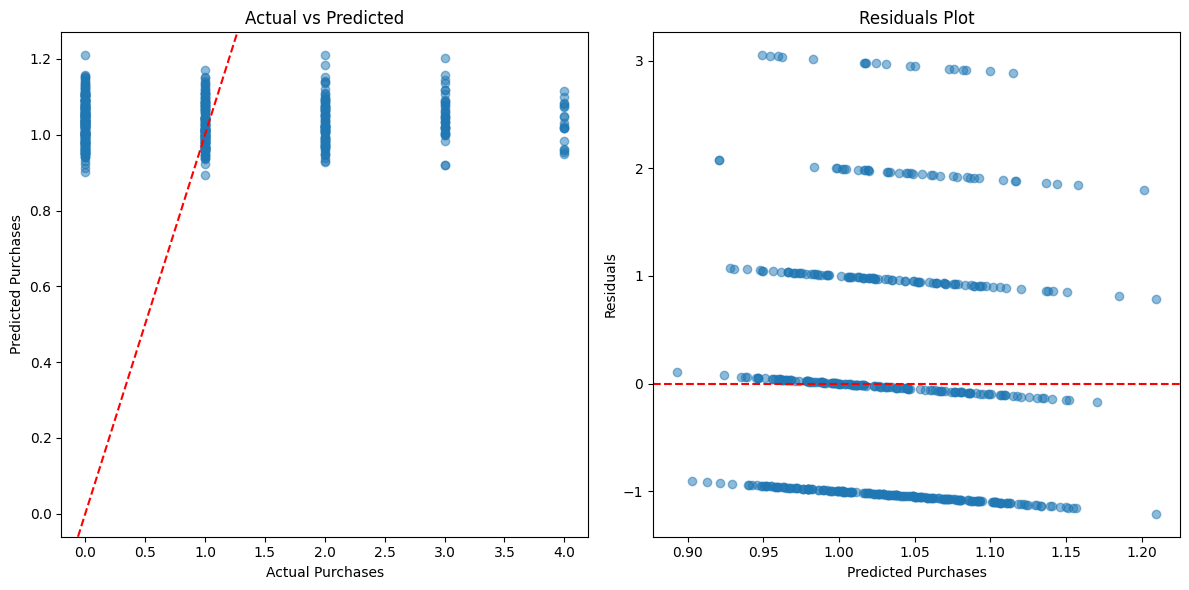